In [17]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import DCD_DAQ
import Siggen_driver
import time

In [18]:
import os 
cwd = os.getcwd()
print(cwd)

/home/rista/Faks/Diplomski rad/Python scripts/Measuring _inductance


In [148]:
samples = []
frequncy = []

for exp in range(1,6):
    for freq in range(1,10):
        filename = f"saves/samples{freq}e{exp}.npy"
        samples.append(np.load(filename))
        frequncy.append(int(freq*(10**exp)))

samples = np.array(samples,dtype=object)
frequency = np.array(frequncy)
print(samples.shape)


(45, 2, 1000)


In [150]:
current = np.empty(45,dtype=object)

current = (samples[:,0]-samples[:,1])/100.0

print(current.shape)



(45, 1000)


In [88]:
def calcImpedance(V,I):
    Vfft = np.fft.rfft(V,norm='forward')*2
    Ifft = np.fft.rfft(I,norm='forward')*2
    indexV = np.argmax(np.abs(Vfft))
    indexI = np.argmax(np.abs(Ifft))
    # print(f"Voltage : {np.abs(Vfft[indexV])}V, Current : {np.abs(Ifft[indexI])}A")
    impedance = Vfft[indexV]/Ifft[indexI]
    return impedance


In [89]:
def calcIV(V,I):
    Vfft = np.fft.rfft(V,norm='forward')*2
    Ifft = np.fft.rfft(I,norm='forward')*2
    indexV = np.argmax(np.abs(Vfft))
    indexI = np.argmax(np.abs(Ifft))
    # print(f"Voltage : {np.abs(Vfft[indexV])}V, Current : {np.abs(Ifft[indexI])}A")
    return np.abs(Vfft[indexV]),np.abs(Ifft[indexI])


In [151]:
Impedance = np.empty(45,dtype=complex)
Voltage = np.empty(45,dtype=float)
Current = np.empty(45,dtype=float)

for i in range(45):
    V = np.array(samples[i][1],dtype=float)
    I = np.array(current[i],dtype=float)
    Voltage[i],Current[i] = calcIV(V,I)

In [152]:
Impedance = np.empty(45,dtype=complex)
Voltage = np.empty(45,dtype=float)
Current = np.empty(45,dtype=float)

for i in range(45):
    V = np.array(samples[i][1],dtype=float)
    I = np.array(current[i],dtype=float)
    Impedance[i] = calcImpedance(V,I)

In [144]:
inductance = np.imag(Impedance)/(frequency*2*np.pi)



avgL = np.average(inductance[2:-10])
devL = np.std(inductance[2:-10])
print(avgL*1e6,"uH")
print(devL)

4219.884901900773 uH
0.0010180023309228814


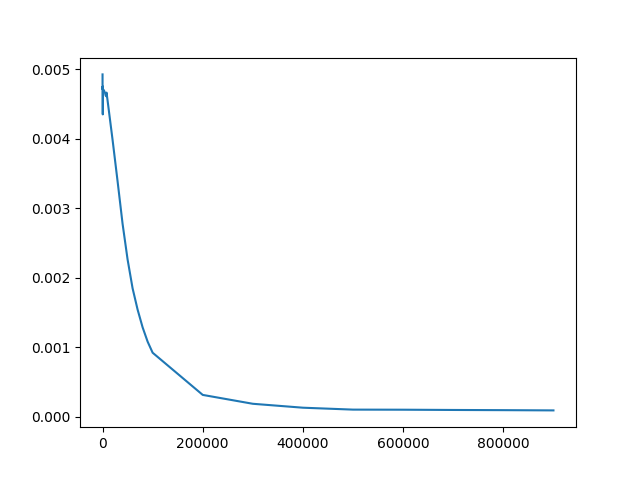

In [156]:
fig = plt.figure()
plt.plot(frequency[2:],inductance[2:])

Text(0.5, 1.0, 'Impedance real')

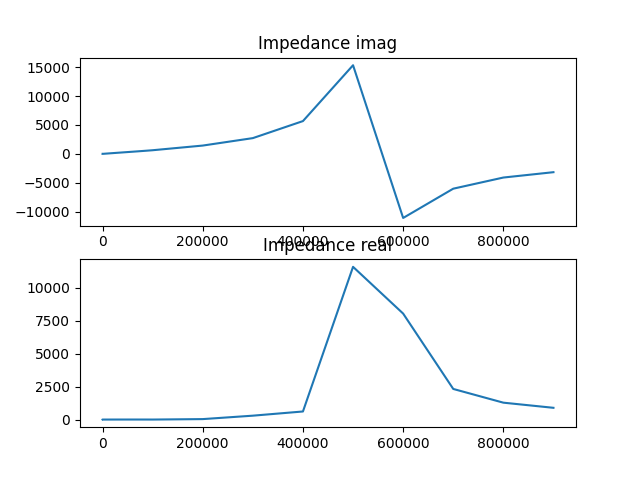

In [154]:
fig, axs = plt.subplots(2,1)
axs[0].plot(frequency,np.imag(Impedance))
axs[0].set_title("Impedance imag")
axs[1].plot(frequency,np.real(Impedance))
axs[1].set_title("Impedance real")

Text(0.5, 1.0, 'Mod current')

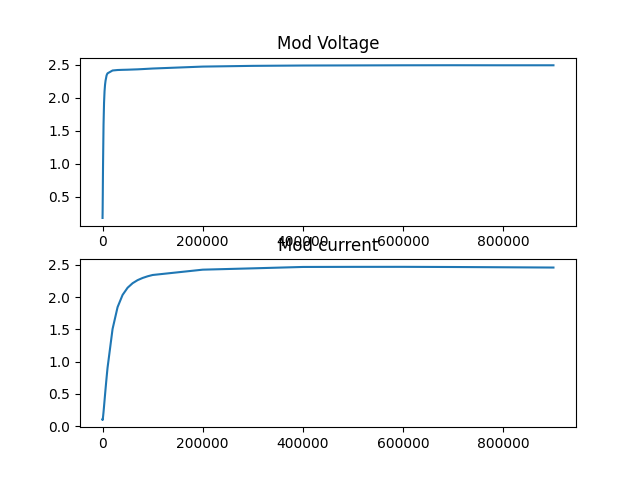

In [155]:
fig, axs = plt.subplots(2,1)
axs[0].plot(frequency,Voltage)
axs[0].set_title("Mod Voltage")
axs[1].plot(frequency,Current)
axs[1].set_title("Mod current")